# Bisection and numerical functions

Approximate square roots by repeatedly halving a bracket.

For positive n, the target root lies in [0, max(1,n)]. The square is monotone there, so the comparison with n selects the half that still contains the root. Each exact-arithmetic iteration halves the interval width. In floating-point arithmetic two endpoints eventually round to the same value. Zero has a simple exact answer.

Preallocating roots fixes its shape. MATLAB indices start at one, so each loop iteration writes to the same index it reads.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.m`

```matlab
values = [0, 0.5, 2, 10, 25];
roots = zeros(size(values));
for j = 1:numel(values)
    n = values(j);
    if n == 0
        continue
    end
    lo = 0;
    hi = max(1, n);
    for iteration = 1:55
        mid = (lo + hi) / 2;
        if mid * mid < n
            lo = mid;
        else
            hi = mid;
        end
    end
    roots(j) = (lo + hi) / 2;
end
fprintf('%.12g ', roots);
```

## Execute the native listing

Preallocating roots fixes its shape. MATLAB indices start at one, so each loop iteration writes to the same index it reads. Write down each array shape and distinguish element-wise arithmetic from matrix operations. The source uses the common MATLAB and GNU Octave language subset.

In [2]:
x = [0, 0.5, 2, 10, 25]
expected = np.asarray([math.sqrt(v) for v in x], dtype=float)
engine, stdout = run_native(here / "native.m")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: GNU Octave (MATLAB-compatible source)
Native stdout: 0 0.707106781187 1.41421356237 3.16227766017 5
Largest absolute difference: 3.1e-12


## Read the output

Accuracy should be checked against an independent implementation on both sides of one. A fixed number of bisection steps is adequate for this small range. The marks show the independent Python reference at each position.

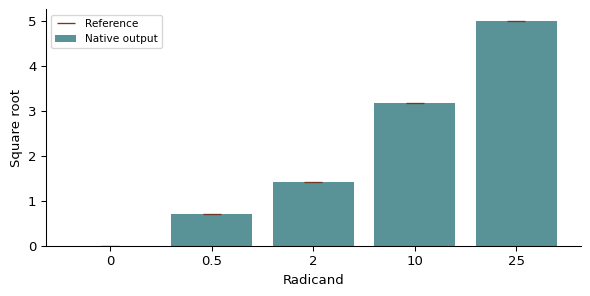

In [3]:
labels = [str(v) for v in x]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Radicand", ylabel="Square root")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

Accuracy should be checked against an independent implementation on both sides of one. A fixed number of bisection steps is adequate for this small range.

## Exercise

Test 0.01, 1 and a larger value. Replace the fixed iteration count with an absolute or relative tolerance and justify the stopping condition.

## References

[MathWorks, MATLAB language fundamentals](https://www.mathworks.com/help/matlab/language-fundamentals.html)

[GNU Octave manual](https://docs.octave.org/latest/)